# Pollux/HACC simulations products
_Tested at NERSC on 2024-03-12 with the `desc-stack-weekly` kernel._

This tutorial introduces the Pollux/HACC data products and how to load them for further developments and HOS studies. It only requires few DESC packages:
- [CCL](https://github.com/LSSTDESC/CCL) for cosmology
- [HealSparse](https://github.com/LSSTDESC/healsparse) to work with maps

In this tutorial, we also use [skyproj](https://github.com/LSSTDESC/skyproj) and [TreeCorr](https://rmjarvis.github.io/TreeCorr/_build/html/index.html) to make cool plots.

## Load pollux
- No need to install it if you simply provide a path.
- If the full package cannot be loaded (eg if some dependencies for the lightcone generation part are unavailable), it will only load the I/O module that is needed to work with data products

In [1]:
from pollux.io import PolluxIO

Only imported pollux.io


In [2]:
PolluxIO?

Init signature:
PolluxIO(
    sim_path,
    seed,
    tomo='SRDv1_nz',
    catalog='poisson',
    interp_pixels=True,
    bias=1,
)
Docstring:      <no docstring>
Init docstring:
`PolluxIO` creates an interface to Pollux/HACC simulations data products.

Parameters
----------
sim_path
    Path to simulation files.
seed
    Seed used for pseudo-independent realizations.
tomo, optional
    Name of the tomographic redshift distributions used for lensing products, by default "SRDv1_nz" (the other option is "kappa_zsnapshots" for individual shells).
catalog, optional
    Source catalog sampling method, by default "poisson" (other options are "uniform" and "multinomial").
interp_pixels, optional
    Whether to interpolate between adjacent pixels when creating the mock catalogs, by default True.
bias, optional
    Value for the galaxy bias used for the Poisson mock catalogs.
File:           /global/u1/j/jmena/pollux_root/pollux_new_new/pollux/io.py
Type:           type
Subclasses:     

## Create a reader interface
This will ensure that you get all the correct paths and, more importantly, the metadata (cosmology, lightcone/shell information, maps information).
- You need to specify the path to simulation files (`sim_path`), the seed used for pseudo-independent realizations (`seed`).
- Optionally, if you need lensing maps, you can specify the n(z)'s that were used, either `"SRDv1_nz"` or `"kappa_Euclid_dndz_fu08_bin1-5"` so far. And the catalog sampling type (`"poisson"` or `"multinomial"`).


In [3]:
import os

# Simulation path
# root_dir = "/global/cfs/cdirs/desc-wl/projects/hos-tt/sims/L845"  # Root directory where sims are stored
root_dir = "/pscratch/sd/j/jmena/HOS_Sims"
sim = "HACC150_3"  # Specific HACC sim used
run = "shells_z51_subsampledensitymax1.5_nside8192"  # Specific run configuration
sim_path = os.path.join(root_dir, sim, run)

# Seed
seed = 0

# PolluxIO interface object
p = PolluxIO(sim_path, seed, tomo="SRDv1_nz", catalog='poisson')

*** PolluxIO ***
 - path = /pscratch/sd/j/jmena/HOS_Sims/HACC150_3/shells_z51_subsampledensitymax1.5_nside8192
 - simulations info
    * box_comoving_density = 14.233481850728298
    * boxsize = 845.0704225352113
    * kind = hacc
    * mass_particles = 2602746430.321433
    * nparticles = 8589934592
    * npix = 805306368
    * nshells = 51
    * nside = 8192
    * nside_c = 32
 - cosmo <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0xe5a3878c1e1378e8


In [4]:
# CCL cosmology object
p.cosmo

<pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0xe5a3878c1e1378e8

In [5]:
# Information about the shells in the lightcone (shell min?max redshifts, snapshot redshifts and particle densities)
p.shell_info

array([( 0, 0.        , 0.        , 0.00802407, 499, 2.86566996e-03, 1.83644294e+05),
       ( 1, 0.01617796, 0.00802407, 0.02446483, 491, 7.75541741e-02, 4.97000066e+06),
       ( 2, 0.03288798, 0.02446483, 0.04145078, 483, 3.06688994e-01, 1.96539325e+07),
       ( 3, 0.05015674, 0.04145078, 0.05900948, 475, 7.17714431e-01, 4.59941871e+07),
       ( 4, 0.06801275, 0.05900948, 0.07717042, 467, 1.33834936e+00, 8.57671075e+07),
       ( 5, 0.08648649, 0.07717042, 0.0959651 , 459, 2.19967607e+00, 1.40964579e+08),
       ( 6, 0.10561056, 0.0959651 , 0.1154273 , 451, 3.33652644e+00, 2.13818776e+08),
       ( 7, 0.12541993, 0.1154273 , 0.13559322, 443, 4.78785634e+00, 3.06826156e+08),
       ( 8, 0.14595211, 0.13559322, 0.15650173, 435, 6.59723257e+00, 4.22778665e+08),
       ( 9, 0.16724739, 0.15650173, 0.17819461, 427, 8.81328574e+00, 5.64792759e+08),
       (10, 0.18934911, 0.17819461, 0.20071685, 419, 1.14902392e+01, 7.36343297e+08),
       (11, 0.21230398, 0.20071685, 0.22411693, 411, 1

Text(0.5, 0, 'Redshift')

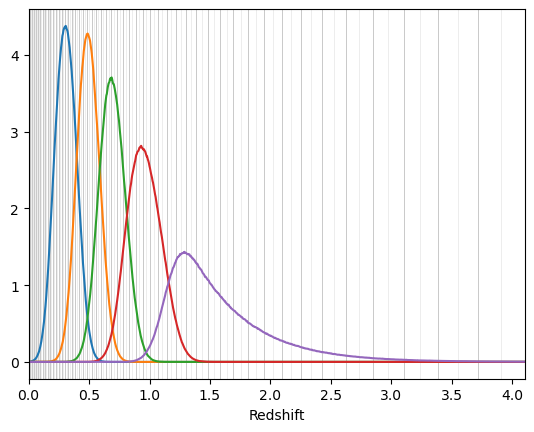

In [6]:
import matplotlib.pyplot as plt

# Redshift distributions used for lensing
for z, nz in p.nzs:
    plt.plot(z, nz)
for z in p.shell_info["zsnapshot"]:
    plt.axvline(z, c=".9", lw=0.5, zorder=-1)
for z in p.shell_info["zmin"]:
    plt.axvline(z, c=".7", lw=0.5, zorder=-1)
plt.xlim(0, p.shell_info["zmax"][-1])
plt.xlabel("Redshift")

## Plot maps
Maps are saved in [HealSparse](https://github.com/LSSTDESC/healsparse) format, see https://healsparse.readthedocs.io/ for map handling.

Two useful things to know is that the healpix version of a HealSparse map `hsp` can be accessed as `hsp[:]` or `hsp.generate_healpix_map()`, and that they are saved in `"NESTED"` order (so use `nestTrue` in healpy functions).

In [7]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

import skyproj
import healsparse
import healpy as hp
import numpy as np

def cool_plot(hsp, count=False, catalog=False):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111)

    lon_0 = 45.0
    lat_0 = 45.0
    delta = 30.0
    sp = skyproj.HammerSkyproj(ax=ax, lon_0=lon_0, lat_0=lat_0)

    if count:
        hsp_log = healsparse.HealSparseMap.make_empty(
            hsp.nside_coverage, hsp.nside_sparse, dtype=hsp.dtype
        )
        hsp_log.update_values_pix(
            hsp.valid_pixels, np.arcsinh(hsp.get_values_pix(hsp.valid_pixels))
        )
        hsp = hsp_log
        colors = ["w", "#043987", "orange", "0.95"]
        nodes = [0.0, 0.65, 0.9, 1.0]
        cmap = LinearSegmentedColormap.from_list("mycmap", list(zip(nodes, colors)))

    else:
        cmap = mpl.cm.RdYlBu_r

    if catalog:
        sp.draw_hpxbin(hsp[1].data["ra"], hsp[1].data["dec"])
    else:
        _ = sp.draw_hspmap(hsp, cmap=cmap)

    sp.set_extent(
        [
            lon_0 - delta / 2.0,
            lat_0 + delta / 2.0,
            lon_0 - delta / 2.0,
            lat_0 + delta / 2.0,
        ]
    )
    sp.set_xlabel("RA", fontsize="medium")
    sp.set_ylabel("DEC", fontsize="medium")

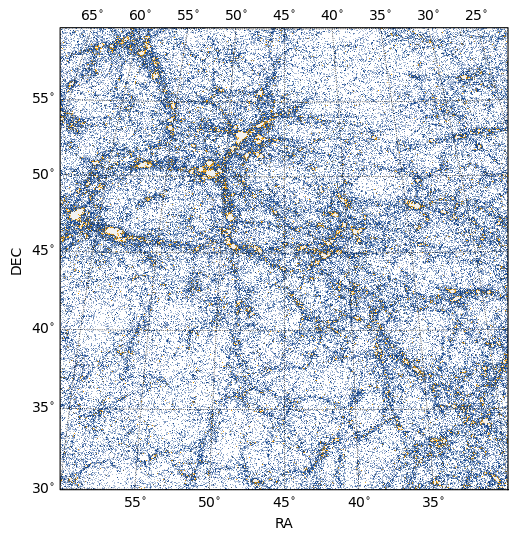

In [8]:
# Particle count map
hsp = p.load_shell(6)
cool_plot(hsp, count=True)

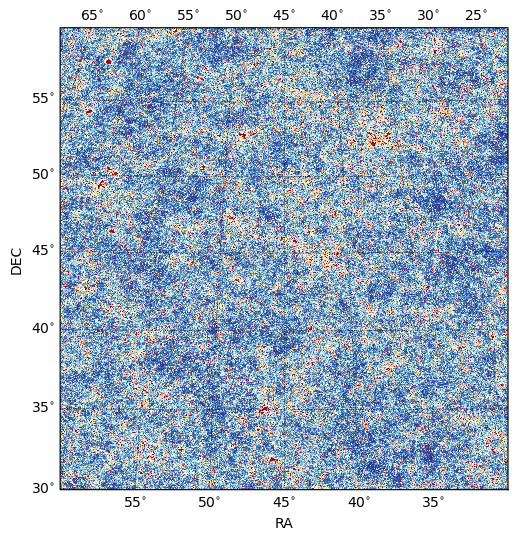

In [9]:
# Convergence maps
hsp = p.load_kappa(2)
cool_plot(hsp)

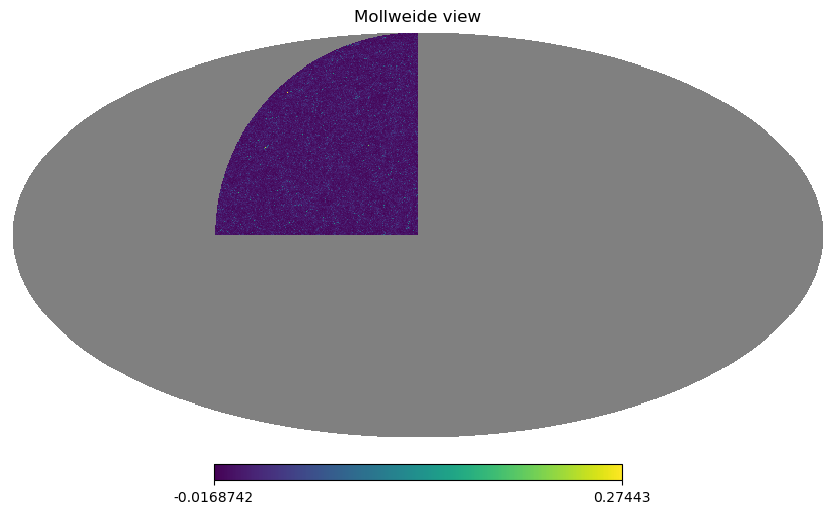

In [10]:
hp.mollview(hsp.generate_healpix_map(), nest=True)

## Catalogs
Catalogs are saved as fits files (one per shell or tomographic bin). Formats differ slight between halo catalogs and galaxy catalogs, but are pretty straightforward.

### Source galaxy catalogs

In [11]:
# Load a source galaxy catalog for a given tomographic bin
cat = p.load_catalog(4)

# The header contain information such as the density and biases of galaxies
cat[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   40 / length of dimension 1                          
NAXIS2  =            111396564 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   10 / number of table fields                         
NBAR_0  =                  6.0                                                  
NBAR_1  =                  6.0                                                  
NBAR_2  =                  6.0                                                  
NBAR_3  =                  6.0                                                  
NBAR_4  =                  6

(0.0, 4.0)

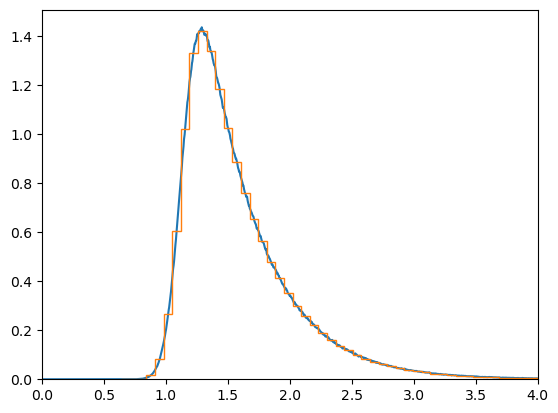

In [12]:
# Redshift distribution of the galaxy catalog matches the input distribution! \o/
plt.plot(p.nzs[4][0], p.nzs[4][1])
plt.hist(cat[1].data["z"], bins=50, density=True, histtype="step")
plt.xlim(0, 4)

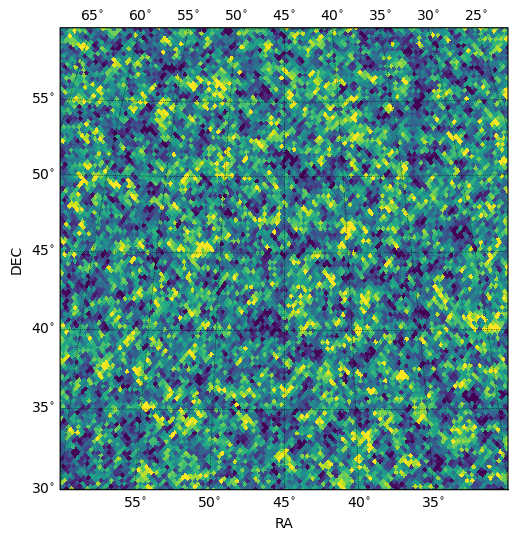

In [13]:
# We can do a bin plot of the positions of galaxies
cool_plot(cat, catalog=True)

### Two-point correlation function
Let's measure the shear two-point correlation function with [TreeCorr](https://rmjarvis.github.io/TreeCorr/_build/html/index.html) and compare to the CCL prediction!

Text(0, 0.5, '$\\theta \\times \\xi_\\pm (\\theta)$')

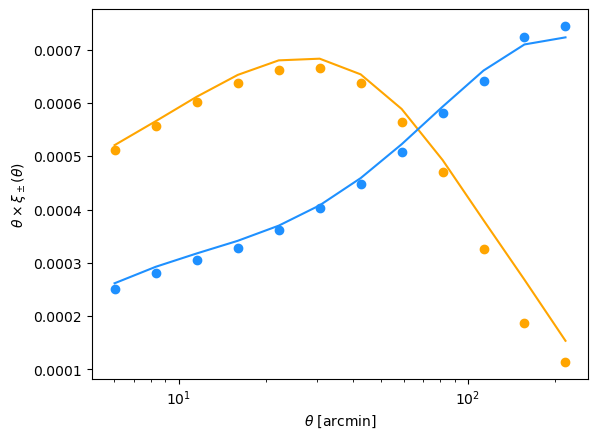

In [14]:
import treecorr, pyccl

# TreeCorr measurements
nsub = 50 # subsampling for speed in this tutorial
_cat = treecorr.Catalog(
    ra=cat[1].data["ra"][::nsub],
    dec=cat[1].data["dec"][::nsub],
    g1=cat[1].data["gamma1"][::nsub],
    g2=-cat[1].data["gamma2"][::nsub],
    ra_units="deg",
    dec_units="deg",
)
gg = treecorr.GGCorrelation(nbins=12, min_sep=5.0, max_sep=250, sep_units="arcmin")
gg.process(_cat)
theta = gg.meanr # average angular separation in each bin

# CCL predictions
tracer = pyccl.WeakLensingTracer(p.cosmo, dndz=p.nzs[4])
ell = np.arange(4 * p.nside)
cl = pyccl.angular_cl(p.cosmo, tracer, tracer, ell)

xip = pyccl.correlations.correlation(
    p.cosmo,
    ell=ell,
    C_ell=cl,
    theta=theta / 60.0,
    type="GG+",
    method="fftlog",
)
xim = pyccl.correlations.correlation(
    p.cosmo,
    ell=ell,
    C_ell=cl,
    theta=theta / 60.0,
    type="GG-",
    method="fftlog",
)

# And plot !
plt.semilogx(theta, theta * xip, color="orange", label=r"$\xi_+$")
plt.semilogx(theta, theta * xim, color="dodgerblue", label=r"$\xi_+$")
plt.semilogx(theta, theta * gg.xip, "o", color="orange")
plt.semilogx(theta, theta * gg.xim, "o", color="dodgerblue")
plt.xlabel(r"$\theta$ [arcmin]")
plt.ylabel(r"$\theta \times \xi_\pm (\theta)$")

### Halo catalogs

In [15]:
# Load halo catalog
haloes = p.load_haloes(0)[1].data

Text(0.5, 0, 'SOD mass [$M_\\odot/h$]')

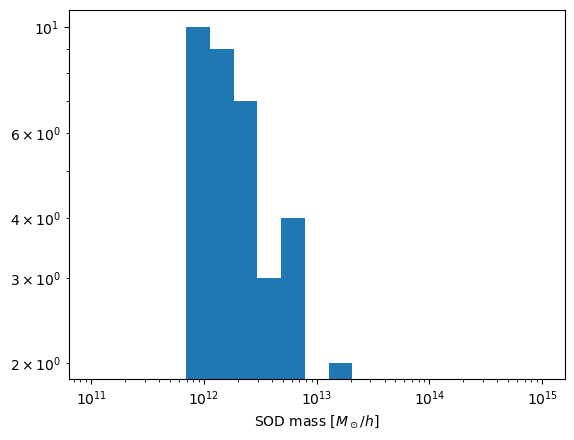

In [16]:
# Plot the halo mass function in that bin (using spherical overdensity masses from HACC)
plt.hist(haloes["sod_halo_mass"], bins=np.geomspace(1e11, 1e15, 20), log=True)
plt.xscale("log")
plt.xlabel("SOD mass [$M_\odot/h$]")

### Tidal fields

In [17]:
t11, t12, t22 = p.load_IA(0)